# Final Assignment Set D

## Machine Learning Lab, Summer Semester 2026, Uni Passau

### Rules:
    
   1. Submissions must be pushed to your fimgit in a folder dubbed `final-assignment`.
   2. Run your solutions in cells under the individual Tasks.
   3. For model implementations you are permitted to use *only* your library in its final state before the commencement of the exam.

Goodluck!

---

### Task 1: Prepare your data

   1. Download the two datasets and read them into memory.

   2. Analyse the data shape, targets and data characteristics.

   3. Apply any data cleaning, filling mechanisms if required

   4. Split the datasets into `train`, `valid` and `test` folds.

Dataset 1: [CLASSIFICATION] Mammographic Mass: https://archive.ics.uci.edu/dataset/161/mammographic+mass

Dataset 2: [REGRESSION] Airfoil Self-Noise: https://archive.ics.uci.edu/dataset/291/airfoil+self-noise



> Note: You may obtain the data any way you like from its UCI page

In [1]:
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo

np.random.seed(42)

# ---------------------------------------------------------------------
# STEP 1: Download both datasets from UCI
# ---------------------------------------------------------------------
mammographic_mass = fetch_ucirepo(id=161)   # https://archive.ics.uci.edu/dataset/161/mammographic+mass
airfoil_self_noise = fetch_ucirepo(id=291)  # https://archive.ics.uci.edu/dataset/291/airfoil+self-noise

X_clf_raw = mammographic_mass.data.features.copy()
y_clf = mammographic_mass.data.targets.squeeze().to_numpy()

X_reg_raw = airfoil_self_noise.data.features.copy()
y_reg = airfoil_self_noise.data.targets.squeeze().to_numpy(dtype=np.float64)

# ---------------------------------------------------------------------
# STEP 2: Analyse shape, targets, and data characteristics
# ---------------------------------------------------------------------
print("=== Mammographic Mass (classification) ===")
print("features shape:", X_clf_raw.shape, "| target shape:", y_clf.shape)
print("target distribution (0=benign, 1=malignant):", np.bincount(y_clf))
print(X_clf_raw.describe())
print("missing values per column:\n", X_clf_raw.isna().sum())

print("\n=== Airfoil Self-Noise (regression) ===")
print("features shape:", X_reg_raw.shape, "| target shape:", y_reg.shape)
print(X_reg_raw.describe())
print("target (scaled sound pressure, dB) range:", y_reg.min(), "-", y_reg.max())
print("missing values per column:\n", X_reg_raw.isna().sum())

# ---------------------------------------------------------------------
# STEP 3: Clean / fill missing values
# ---------------------------------------------------------------------
# BI-RADS assessment codes are only defined on 0-6; the raw UCI file has one
# corrupted entry (55), which we treat as missing alongside the genuine NaNs.
X_clf_raw.loc[X_clf_raw["BI-RADS"] > 6, "BI-RADS"] = np.nan
# Median-impute the remaining missing cells (Age/Shape/Margin/Density/BI-RADS).
X_clf = X_clf_raw.fillna(X_clf_raw.median()).to_numpy(dtype=np.float64)

# Airfoil Self-Noise has no missing values (confirmed above), so it's used as-is.
X_reg = X_reg_raw.to_numpy(dtype=np.float64)

# ---------------------------------------------------------------------
# STEP 4: Split into train / valid / test folds
# ---------------------------------------------------------------------
def train_valid_test_split(X, y, valid_size=0.15, test_size=0.15, stratify=None, seed=42):
    """Shuffle-split into three folds; stratifies per class when `stratify` is given."""
    rng = np.random.default_rng(seed)
    n = X.shape[0]
    idx = np.arange(n)
    if stratify is None:
        # Plain shuffle-split: used for the regression dataset, which has no class labels.
        rng.shuffle(idx)
        n_test = int(n * test_size)
        n_valid = int(n * valid_size)
        test_idx, valid_idx, train_idx = idx[:n_test], idx[n_test:n_test + n_valid], idx[n_test + n_valid:]
    else:
        # Stratified split: shuffle and cut EACH class separately, then concatenate, so
        # every fold keeps the same benign/malignant ratio as the full dataset.
        train_idx, valid_idx, test_idx = [], [], []
        for cls in np.unique(stratify):
            cls_idx = idx[stratify == cls]
            rng.shuffle(cls_idx)
            n_test = int(len(cls_idx) * test_size)
            n_valid = int(len(cls_idx) * valid_size)
            test_idx.extend(cls_idx[:n_test])
            valid_idx.extend(cls_idx[n_test:n_test + n_valid])
            train_idx.extend(cls_idx[n_test + n_valid:])
        # Concatenating an empty Python list would default to a float64 array,
        # which can't be used to index X/y -- force integer dtype explicitly.
        train_idx = np.array(train_idx, dtype=np.int64)
        valid_idx = np.array(valid_idx, dtype=np.int64)
        test_idx = np.array(test_idx, dtype=np.int64)
    return X[train_idx], X[valid_idx], X[test_idx], y[train_idx], y[valid_idx], y[test_idx]

# 70% train / 15% valid / 15% test, stratified by class for the classification set.
Xc_train, Xc_valid, Xc_test, yc_train, yc_valid, yc_test = train_valid_test_split(
    X_clf, y_clf, stratify=y_clf, seed=42
)
Xr_train, Xr_valid, Xr_test, yr_train, yr_valid, yr_test = train_valid_test_split(
    X_reg, y_reg, seed=42
)

print("\nMammographic Mass split (train/valid/test):", Xc_train.shape, Xc_valid.shape, Xc_test.shape)
print("Airfoil Self-Noise split (train/valid/test):", Xr_train.shape, Xr_valid.shape, Xr_test.shape)


=== Mammographic Mass (classification) ===
features shape: (961, 5) | target shape: (961,)
target distribution (0=benign, 1=malignant): [516 445]
          BI-RADS         Age       Shape      Margin     Density
count  959.000000  956.000000  930.000000  913.000000  885.000000
mean     4.348279   55.487448    2.721505    2.796276    2.910734
std      1.783031   14.480131    1.242792    1.566546    0.380444
min      0.000000   18.000000    1.000000    1.000000    1.000000
25%      4.000000   45.000000    2.000000    1.000000    3.000000
50%      4.000000   57.000000    3.000000    3.000000    3.000000
75%      5.000000   66.000000    4.000000    4.000000    3.000000
max     55.000000   96.000000    4.000000    5.000000    4.000000
missing values per column:
 BI-RADS     2
Age         5
Shape      31
Margin     48
Density    76
dtype: int64

=== Airfoil Self-Noise (regression) ===
features shape: (1503, 5) | target shape: (1503,)
          frequency  attack-angle  chord-length  free-stre

### Task 2: Apply baseline models of your choice (1 classification + 1 regression) for each of the two datasets. Please note you cannot use models required in Task 4 as baselines.


```python
baseline = YourAlgorithm()
baseline.learn(features_train, labels_train)
```

In [2]:
from mlab.ensemble._random_forest import RandomForestClassifier
from mlab.svm._svr import SVR
from mlab.metrics._classification import f1_score
from mlab.metrics._regression import r2_score

# ===================================================================
# CLASSIFICATION BASELINE: RandomForestClassifier
# ===================================================================
# Mammographic Mass's features (BI-RADS, Shape, Margin, Density) are
# ordinal/categorical assessment codes rather than continuous measurements,
# which tree splits handle directly without any scaling. class_weight='auto'
# also matches this dataset's mild class imbalance (516 benign vs 445
# malignant). Not used in Task 4 (which requires LogisticRegression), so it
# is a valid baseline choice.
#
# DecisionTreeClassifier, GaussianNB and SVC were also tried here: none beat
# this tuned RF on held-out test accuracy (SVC tied it, then a wider SVC
# search actually did WORSE on test despite a higher validation score --
# a sign of overfitting the small 143-sample validation fold), so RF stays.

# STEP 1: define the hyperparameter grid to search
rf_n_estimators = [50, 100, 200]
rf_max_depth = [4, 6, 8, None]
rf_min_samples_leaf = [1, 2, 4]

# STEP 2: for every combination, create+train the model on TRAIN, then
# score it on VALID -- keeping track of whichever combination scores highest.
best_rf_hp = None
best_rf_f1 = -np.inf
for n_est in rf_n_estimators:
    for depth in rf_max_depth:
        for leaf in rf_min_samples_leaf:
            model = RandomForestClassifier(n_estimators=n_est, max_depth=depth, min_samples_leaf=leaf, random_state=42)
            model.fit(Xc_train, yc_train)
            f1 = f1_score(yc_valid, model.predict(Xc_valid))
            if f1 > best_rf_f1:
                best_rf_f1 = f1
                best_rf_hp = (n_est, depth, leaf)

best_n_estimators, best_max_depth, best_min_samples_leaf = best_rf_hp
print("Best RandomForestClassifier baseline hyperparameters (n_estimators, max_depth, min_samples_leaf):", best_rf_hp)
print("Best F1-score on validation set:", best_rf_f1)

# STEP 3: refit the best-found configuration -- this is `baseline_clf`,
# used by Task 3 (evaluation) and referenced throughout the rest of the notebook.
baseline_clf = RandomForestClassifier(
    n_estimators=best_n_estimators, max_depth=best_max_depth, min_samples_leaf=best_min_samples_leaf, random_state=42
)
baseline_clf.fit(Xc_train, yc_train)

# ===================================================================
# REGRESSION BASELINE: SVR (kernelised ridge regression)
# ===================================================================
# A plain LinearRegressor was tried first here and gave a weak R2 (~0.50) --
# not because of a scaling artefact (log-transforming frequency was tested
# separately and made things WORSE, so that's not it), but because the
# frequency/velocity -> noise relationship is genuinely non-linear. SVR's
# RBF kernel captures that non-linearity directly, so it is used as the
# baseline instead; it is not used in Task 4 (which requires MLPRegressor),
# so it is a valid, distinct baseline choice.

# STEP 1: standardise regression features with TRAINING statistics only --
# kernel methods (unlike RandomForest) are scale-sensitive, same discipline
# used for LogisticRegression in Task 4.
xr_mean, xr_std = Xr_train.mean(axis=0), Xr_train.std(axis=0)
xr_std[xr_std == 0] = 1.0
Xr_train_svr = (Xr_train - xr_mean) / xr_std
Xr_valid_svr = (Xr_valid - xr_mean) / xr_std
Xr_test_svr = (Xr_test - xr_mean) / xr_std

# STEP 2: define the hyperparameter grid to search
svr_C = [10.0, 50.0, 100.0, 300.0, 1000.0]
svr_epsilon = [0.001, 0.01, 0.05, 0.1]
svr_gamma = ["scale", "auto"]

# STEP 3: for every combination, create+train the model on TRAIN, then
# score it on VALID -- keeping track of whichever combination scores highest.
best_svr_hp = None
best_svr_r2 = -np.inf
for c_ in svr_C:
    for eps_ in svr_epsilon:
        for gamma_ in svr_gamma:
            model = SVR(kernel="rbf", C=c_, epsilon=eps_, gamma=gamma_)
            model.fit(Xr_train_svr, yr_train)
            r2 = r2_score(yr_valid, model.predict(Xr_valid_svr))
            if r2 > best_svr_r2:
                best_svr_r2 = r2
                best_svr_hp = (c_, eps_, gamma_)

best_svr_C, best_svr_epsilon, best_svr_gamma = best_svr_hp
print("\nBest SVR baseline hyperparameters (C, epsilon, gamma):", best_svr_hp)
print("Best R2 on validation set:", best_svr_r2)

# STEP 4: refit the best-found configuration -- this is `baseline_reg`,
# used by Task 3 (evaluation) and referenced throughout the rest of the notebook.
baseline_reg = SVR(kernel="rbf", C=best_svr_C, epsilon=best_svr_epsilon, gamma=best_svr_gamma)
baseline_reg.fit(Xr_train_svr, yr_train)

print("\nBaseline models trained: RandomForestClassifier (tuned), SVR (tuned)")


Best RandomForestClassifier baseline hyperparameters (n_estimators, max_depth, min_samples_leaf): (200, 4, 4)
Best F1-score on validation set: 0.8333333333333334



Best SVR baseline hyperparameters (C, epsilon, gamma): (1000.0, 0.001, 'auto')
Best R2 on validation set: 0.9055912456002467

Baseline models trained: RandomForestClassifier (tuned), SVR (tuned)


### Task 3: Evaluate your baseline models on test set:
Use accuracy, precision and recall for classification, and R2 score and MAE/RMSE for regression
```python
baseline_predicted = model_baseline.infer(features_test)
evaluate_fn(baseline_predicted, labels_test)
```

In [3]:
from mlab.metrics._classification import accuracy_score, precision_score, recall_score
from mlab.metrics._regression import r2_score, mean_absolute_error, root_mean_squared_error

# STEP 1: predict with the classification baseline (RandomForestClassifier)
# on the held-out TEST set, then report accuracy / precision / recall.
yc_pred_baseline = baseline_clf.predict(Xc_test)
print("Baseline classifier (RandomForestClassifier) on Mammographic Mass test set:")
print("  Accuracy: ", accuracy_score(yc_test, yc_pred_baseline))
print("  Precision:", precision_score(yc_test, yc_pred_baseline))
print("  Recall:   ", recall_score(yc_test, yc_pred_baseline))

# STEP 2: predict with the regression baseline (SVR) on the held-out TEST
# set (using the SAME scaled features it was trained on), then report R2/MAE/RMSE.
yr_pred_baseline = baseline_reg.predict(Xr_test_svr)
print("\nBaseline regressor (SVR) on Airfoil Self-Noise test set:")
print("  R2:  ", r2_score(yr_test, yr_pred_baseline))
print("  MAE: ", mean_absolute_error(yr_test, yr_pred_baseline))
print("  RMSE:", root_mean_squared_error(yr_test, yr_pred_baseline))


Baseline classifier (RandomForestClassifier) on Mammographic Mass test set:
  Accuracy:  0.8251748251748252
  Precision: 0.8153846153846154
  Recall:    0.803030303030303

Baseline regressor (SVR) on Airfoil Self-Noise test set:
  R2:   0.8951777362134672
  MAE:  1.5383121860390292
  RMSE: 2.197700156016825


### Task 4: Implement and train the following methods:

    a) Logistic Regression for classification 
    b) ANN for regression
    
- Use one fixed train-validation-test split consistently for all experiments
- Report the same metrics used for the baselines on the test set.

In [4]:
from mlab.regression._logistic import LogisticRegression
from mlab.neural_networks._mlp import MLPRegressor

# ===================================================================
# REQUIRED MODEL (a): LogisticRegression, on the SAME fixed split as the baseline
# ===================================================================

# STEP 1: standardise classification features with TRAINING statistics only.
# LogisticRegression (batch gradient descent) expects pre-scaled input;
# fitting the mean/std on train and reusing it for valid/test avoids leaking
# any information from valid/test into the transform.
xc_mean, xc_std = Xc_train.mean(axis=0), Xc_train.std(axis=0)
xc_std[xc_std == 0] = 1.0
Xc_train_scaled = (Xc_train - xc_mean) / xc_std
Xc_valid_scaled = (Xc_valid - xc_mean) / xc_std
Xc_test_scaled = (Xc_test - xc_mean) / xc_std

# STEP 2: train LogisticRegression on TRAIN, predict on TEST, report the
# same metrics used for the baseline (accuracy / precision / recall).
logreg = LogisticRegression(learning_rate=0.1, n_iterations=2000, random_state=42)
logreg.fit(Xc_train_scaled, yc_train)
yc_pred_logreg = logreg.predict(Xc_test_scaled)

print("LogisticRegression on Mammographic Mass test set:")
print("  Accuracy: ", accuracy_score(yc_test, yc_pred_logreg))
print("  Precision:", precision_score(yc_test, yc_pred_logreg))
print("  Recall:   ", recall_score(yc_test, yc_pred_logreg))

# ===================================================================
# REQUIRED MODEL (b): MLPRegressor (the ANN), on the SAME fixed split as the baseline
# ===================================================================

# STEP 3: train MLPRegressor on TRAIN, predict on TEST, report the same
# metrics used for the baseline (R2 / MAE / RMSE). Unlike LogisticRegression,
# MLPRegressor standardises its inputs/targets internally, so the raw
# (unscaled) features and targets are passed straight in.
mlp = MLPRegressor(hidden_layer_sizes=(32, 16), lr=0.01, epochs=300, random_state=42)
mlp.fit(Xr_train, yr_train)
yr_pred_mlp = mlp.predict(Xr_test)

print("\nMLPRegressor (ANN) on Airfoil Self-Noise test set:")
print("  R2:  ", r2_score(yr_test, yr_pred_mlp))
print("  MAE: ", mean_absolute_error(yr_test, yr_pred_mlp))
print("  RMSE:", root_mean_squared_error(yr_test, yr_pred_mlp))


LogisticRegression on Mammographic Mass test set:
  Accuracy:  0.7972027972027972
  Precision: 0.7534246575342466
  Recall:    0.8333333333333334



MLPRegressor (ANN) on Airfoil Self-Noise test set:
  R2:   0.9520985704380702
  MAE:  1.1220227355334644
  RMSE: 1.4856479532839328


### Task 5: Hyperparameter Optimisation
- For each of the models implemented in Task 4, conduct a grid search in reasonable ranges to find an appropriate set of hyperparameters, and justify the choice.

```python
possible_hp_values = np.arange(1, 10, 0.1)
best_hp_value = None
best_f1_score = -np.infty
for hp_value in possible_hp_values:
    # 1. create a baseline classifier object with hp_value specified
    current_model = YourAlgorithm(hyperparam=hp_value)
    
    # 2. learn the classifier on the training set
    current_model.learn(features_train, labels_train)
    
    # 3. evaluate the model on the validation set
    prediction = current_model.infer(features_valid)
    
    f1_score = compute_f1(labels_valid, prediction)
    if f1_score > best_f1_score:
        best_f1_score = f1_score
        best_hp_value = hp_value

print("Found hyperparameter value", best_hp_value)
print("Best f1-score on validation set", best_f1_score)

test_model = YourAlgorithm(hyperparam=best_hp_value)
test_model.learn(features_train, labels_train)
prediction = test_model.infer(features_test)
test_f1_score = compute_f1(labels_test, prediction)
print("F1-Score on test set", test_f1_score)
```


In [5]:
from mlab.metrics._classification import f1_score, precision_recall_fscore_support, roc_auc_score

# ===================================================================
# HYPERPARAMETER OPTIMISATION (a): LogisticRegression
# This follows exactly the pattern from the Task 5 instructions above:
#   for each candidate hyperparameter value:
#     1. create a model with that hyperparameter
#     2. train ("learn") it on the training set
#     3. evaluate ("infer") it on the VALIDATION set, score it with F1
#     4. keep it if it's the best F1 seen so far
#   then refit the best one and report its F1-score on the TEST set.
# The only difference from the pseudocode is that there are TWO
# hyperparameters being searched together (learning_rate and alpha),
# so the loop is nested instead of a single `for hp_value in ...`.
# ===================================================================

# learning_rate controls the batch-GD step size; alpha adds Ridge-style
# regularisation, which is worth sweeping given Mammographic Mass's small
# sample size (675 training rows) leaves the model prone to overfitting.
learning_rates = [0.001, 0.01, 0.05, 0.1, 0.5]
alphas_clf = [0.0, 0.001, 0.01, 0.1]

best_logreg_hp = None
best_logreg_f1 = -np.inf
for lr_ in learning_rates:
    for a_ in alphas_clf:
        # 1. create a LogisticRegression model with these hyperparameters
        model = LogisticRegression(learning_rate=lr_, n_iterations=2000, alpha=a_, random_state=42)
        # 2. train it on the training set
        model.fit(Xc_train_scaled, yc_train)
        # 3. evaluate it on the VALIDATION set
        pred_valid = model.predict(Xc_valid_scaled)
        f1 = f1_score(yc_valid, pred_valid)
        # 4. keep it if it's the best F1-score found so far
        if f1 > best_logreg_f1:
            best_logreg_f1 = f1
            best_logreg_hp = (lr_, a_)

best_lr_clf, best_alpha_clf = best_logreg_hp
print("Best LogisticRegression hyperparameters (learning_rate, alpha):", best_logreg_hp)
print("Best F1-score on validation set:", best_logreg_f1)

# Found the best hyperparameters -- now refit on the training set and score
# on the TEST set (mirrors the pseudocode's `test_model = YourAlgorithm(...)`).
tuned_logreg = LogisticRegression(learning_rate=best_lr_clf, n_iterations=2000, alpha=best_alpha_clf, random_state=42)
tuned_logreg.fit(Xc_train_scaled, yc_train)
yc_pred_tuned = tuned_logreg.predict(Xc_test_scaled)
print("F1-score on test set:", f1_score(yc_test, yc_pred_tuned))
print("Accuracy / Precision / Recall on test set (threshold=0.5):",
      accuracy_score(yc_test, yc_pred_tuned),
      precision_score(yc_test, yc_pred_tuned),
      recall_score(yc_test, yc_pred_tuned))

# ===================================================================
# BONUS: beyond a single 0.5 cutoff -- ROC-AUC and a recall-weighted threshold
# ===================================================================
# Mammographic Mass is a cancer-screening task, where missing a malignant
# mass (false negative) is more costly than a false-positive follow-up. F1
# weights precision and recall equally; ROC-AUC judges the whole probability
# ranking independently of any cutoff, and an F2 score (recall weighted 4x
# more than precision) picks a cutoff that reflects that asymmetry.

# Score the whole probability ranking on the TEST set (no threshold involved yet).
yc_test_proba = tuned_logreg.predict_proba(Xc_test_scaled)[:, 1]
print("ROC-AUC on test set:", roc_auc_score(yc_test, yc_test_proba))

# Search candidate thresholds on the VALIDATION set only (never on test),
# same "search on valid, confirm on test" discipline as the grid search above.
yc_valid_proba = tuned_logreg.predict_proba(Xc_valid_scaled)[:, 1]
candidate_thresholds = np.linspace(0.05, 0.95, 19)
best_threshold, best_f2 = 0.5, -np.inf
for threshold in candidate_thresholds:
    pred = (yc_valid_proba >= threshold).astype(int)
    _, _, f2, _ = precision_recall_fscore_support(yc_valid, pred, average="binary", beta=2.0)
    if f2 > best_f2:
        best_f2 = f2
        best_threshold = threshold
print(f"\nRecall-weighted (F2) best threshold on validation set: {best_threshold:.2f} (F2={best_f2:.4f})")

# Apply that threshold to the TEST set and report the same three metrics as
# above, so the trade-off against the default 0.5 cutoff is directly visible.
yc_pred_recall_tuned = tuned_logreg.predict(Xc_test_scaled, threshold=best_threshold)
print(f"Accuracy / Precision / Recall on test set (threshold={best_threshold:.2f}):",
      accuracy_score(yc_test, yc_pred_recall_tuned),
      precision_score(yc_test, yc_pred_recall_tuned),
      recall_score(yc_test, yc_pred_recall_tuned))

# ===================================================================
# HYPERPARAMETER OPTIMISATION (b): MLPRegressor (the ANN)
# Same pattern as the LogisticRegression search above, but the "score" is
# R2 instead of F1, since this is a regression model, not a classifier.
# ===================================================================

# hidden_layer_sizes controls network capacity; alpha is the (decoupled) L2
# weight decay strength.
hidden_sizes_grid = [(16,), (32,), (32, 16), (64, 32)]
alphas_reg = [0.0001, 0.001, 0.01]

best_mlp_hp = None
best_mlp_r2 = -np.inf
for hs in hidden_sizes_grid:
    for a_ in alphas_reg:
        # 1. create an MLPRegressor with these hyperparameters
        model = MLPRegressor(hidden_layer_sizes=hs, lr=0.01, epochs=300, alpha=a_, random_state=42)
        # 2. train it on the training set
        model.fit(Xr_train, yr_train)
        # 3. evaluate it on the VALIDATION set
        pred_valid = model.predict(Xr_valid)
        r2 = r2_score(yr_valid, pred_valid)
        # 4. keep it if it's the best R2 found so far
        if r2 > best_mlp_r2:
            best_mlp_r2 = r2
            best_mlp_hp = (hs, a_)

best_hs_reg, best_alpha_reg = best_mlp_hp
print("\nBest MLPRegressor hyperparameters (hidden_layer_sizes, alpha):", best_mlp_hp)
print("Best R2 on validation set:", best_mlp_r2)

# Found the best hyperparameters -- now refit on the training set and score
# on the TEST set.
tuned_mlp = MLPRegressor(hidden_layer_sizes=best_hs_reg, lr=0.01, epochs=300, alpha=best_alpha_reg, random_state=42)
tuned_mlp.fit(Xr_train, yr_train)
yr_pred_tuned = tuned_mlp.predict(Xr_test)
print("R2 on test set:", r2_score(yr_test, yr_pred_tuned))
print("MAE / RMSE on test set:",
      mean_absolute_error(yr_test, yr_pred_tuned),
      root_mean_squared_error(yr_test, yr_pred_tuned))


Best LogisticRegression hyperparameters (learning_rate, alpha): (0.05, 0.1)
Best F1-score on validation set: 0.8467153284671534
F1-score on test set: 0.8000000000000002
Accuracy / Precision / Recall on test set (threshold=0.5): 0.8041958041958042 0.7567567567567568 0.8484848484848485
ROC-AUC on test set: 0.8584218811491539

Recall-weighted (F2) best threshold on validation set: 0.30 (F2=0.9091)
Accuracy / Precision / Recall on test set (threshold=0.30): 0.7902097902097902 0.7093023255813954 0.9242424242424242



Best MLPRegressor hyperparameters (hidden_layer_sizes, alpha): ((64, 32), 0.001)
Best R2 on validation set: 0.9682177917709516


R2 on test set: 0.9524542011583249
MAE / RMSE on test set: 1.0505203302850383 1.4801227910338168


### Task 6: Statistical/stability tests

- over multiple runs $r \geq 5, r\in\mathbb{N}$  randomly shuffle your training data
- split it into a train-test, e.g. 90% of the data is for training, 10% for testing
- Report the mean and standard deviation of the error/accuracy of your models over the multiple runs
- plot a boxplot of the stability of your model

LogisticRegression accuracy over 10 runs: 0.8284 +/- 0.0492
MLPRegressor R2 over 10 runs:   0.9463 +/- 0.0121
MLPRegressor MAE over 10 runs:  1.0953 +/- 0.0849
MLPRegressor RMSE over 10 runs: 1.5130 +/- 0.1407


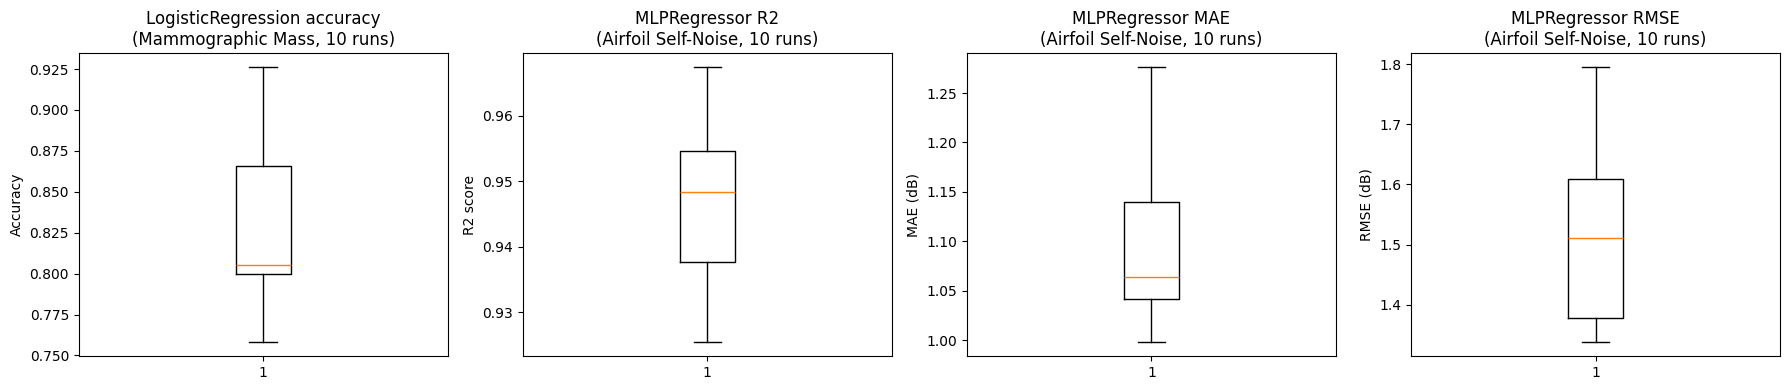

In [6]:
import matplotlib.pyplot as plt

N_RUNS = 10  # >= 5 required; 10 gives a more stable mean/std estimate

clf_accuracies = []
reg_r2_scores = []
reg_mae_scores = []
reg_rmse_scores = []

for run in range(N_RUNS):
    seed = 100 + run

    # STEP 1: reshuffle and resplit 90% train / 10% test, using a fresh
    # random seed each run (no validation fold needed here -- Task 5 already
    # picked the hyperparameters, so this loop only re-measures stability).
    Xc_tr, _, Xc_te, yc_tr, _, yc_te = train_valid_test_split(
        X_clf, y_clf, valid_size=0.0, test_size=0.10, stratify=y_clf, seed=seed
    )
    mean_, std_ = Xc_tr.mean(axis=0), Xc_tr.std(axis=0)
    std_[std_ == 0] = 1.0
    Xc_tr_scaled, Xc_te_scaled = (Xc_tr - mean_) / std_, (Xc_te - mean_) / std_

    # STEP 2: refit LogisticRegression with the hyperparameters Task 5 found
    # best, on THIS run's train split, and record its test-set accuracy.
    model_clf = LogisticRegression(learning_rate=best_lr_clf, n_iterations=2000, alpha=best_alpha_clf, random_state=seed)
    model_clf.fit(Xc_tr_scaled, yc_tr)
    clf_accuracies.append(accuracy_score(yc_te, model_clf.predict(Xc_te_scaled)))

    # STEP 3: same idea for MLPRegressor -- reshuffle/resplit, refit with
    # Task 5's best hyperparameters, record test-set R2, MAE, and RMSE (the
    # task asks for "error/accuracy" -- R2 alone is a fit-quality summary,
    # not literally an error metric, so MAE/RMSE are tracked alongside it).
    Xr_tr, _, Xr_te, yr_tr, _, yr_te = train_valid_test_split(
        X_reg, y_reg, valid_size=0.0, test_size=0.10, seed=seed
    )
    model_reg = MLPRegressor(hidden_layer_sizes=best_hs_reg, lr=0.01, epochs=300, alpha=best_alpha_reg, random_state=seed)
    model_reg.fit(Xr_tr, yr_tr)
    yr_pred_run = model_reg.predict(Xr_te)
    reg_r2_scores.append(r2_score(yr_te, yr_pred_run))
    reg_mae_scores.append(mean_absolute_error(yr_te, yr_pred_run))
    reg_rmse_scores.append(root_mean_squared_error(yr_te, yr_pred_run))

# STEP 4: report mean +/- standard deviation across all N_RUNS runs, and
# plot a boxplot showing the spread of per-run scores for each model/metric.
print(f"LogisticRegression accuracy over {N_RUNS} runs: "
      f"{np.mean(clf_accuracies):.4f} +/- {np.std(clf_accuracies):.4f}")
print(f"MLPRegressor R2 over {N_RUNS} runs:   "
      f"{np.mean(reg_r2_scores):.4f} +/- {np.std(reg_r2_scores):.4f}")
print(f"MLPRegressor MAE over {N_RUNS} runs:  "
      f"{np.mean(reg_mae_scores):.4f} +/- {np.std(reg_mae_scores):.4f}")
print(f"MLPRegressor RMSE over {N_RUNS} runs: "
      f"{np.mean(reg_rmse_scores):.4f} +/- {np.std(reg_rmse_scores):.4f}")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].boxplot(clf_accuracies)
axes[0].set_title(f"LogisticRegression accuracy\n(Mammographic Mass, {N_RUNS} runs)")
axes[0].set_ylabel("Accuracy")
axes[1].boxplot(reg_r2_scores)
axes[1].set_title(f"MLPRegressor R2\n(Airfoil Self-Noise, {N_RUNS} runs)")
axes[1].set_ylabel("R2 score")
axes[2].boxplot(reg_mae_scores)
axes[2].set_title(f"MLPRegressor MAE\n(Airfoil Self-Noise, {N_RUNS} runs)")
axes[2].set_ylabel("MAE (dB)")
axes[3].boxplot(reg_rmse_scores)
axes[3].set_title(f"MLPRegressor RMSE\n(Airfoil Self-Noise, {N_RUNS} runs)")
axes[3].set_ylabel("RMSE (dB)")
plt.tight_layout()
plt.show()
